In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, BackupAndRestore, EarlyStopping
from tensorflow.keras.utils import to_categorical

# import kagglehub

RANDOM_KEY=26
SIZE_IMAGE=224
BATCH_SIZE = 45
EPOCHS = 10
AUTOTUNE = tf.data.AUTOTUNE

DATA_DIR = "/kaggle/input/datasets/hamzahajjaji/dataset-brief-5/Data"

# Download latest version
# path = kagglehub.dataset_download("karapy/neurovision")

# DATA_DIR = Path("/root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data")

#### Charger les images

In [2]:
def loead_images(data_dire:str):
    images = []
    labels = []

    extention_allow = {".jpeg", ".jpg", ".bmp", ".png"}

    for folder in Path(data_dire).iterdir():
        if not folder.is_dir():
            continue

        label = folder.name

        for file in folder.iterdir():
            if file.suffix.lower() not in extention_allow:
                continue

            images.append(str(file))
            labels.append(label)
    return images, labels

images_path, labels = loead_images(DATA_DIR)


print("Nomber d'images :", len(images_path))
print("Nomber de labels :", len(labels))

print('Example de image:', images_path[0])
print('Example de Label:', labels[0])

Nomber d'images : 7023
Nomber de labels : 7023
Example de image: /kaggle/input/datasets/hamzahajjaji/dataset-brief-5/Data/glioma/Te-glTr_0000.jpg
Example de Label: glioma


#### Convertir les listes en tableaux NumPy

In [3]:
def convert_to_numpay_table(images, labels):
    return np.array(images), np.array(labels)

X, y = convert_to_numpay_table(images_path, labels)

#### Afficher un échantillon d'images

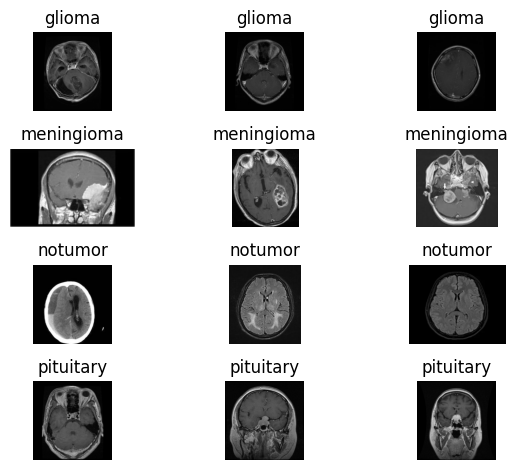

In [4]:
def afficher_images_echntillon(images, labels):
    classes = np.unique(labels)
    _, axes = plt.subplots(len(classes), 3)

    for i, classe in enumerate(classes):
        images_index = np.where(labels == classe)[0][:3]
        for j, index in enumerate(images_index):
            # loead et converter BGR to RGB
            image = cv2.cvtColor(cv2.imread(images[index]), cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(image)
            axes[i, j].set_title(classe)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.show()

classes = np.unique(y)

afficher_images_echntillon(X, y)

#### Afficher la distribution et l'équilibre des images

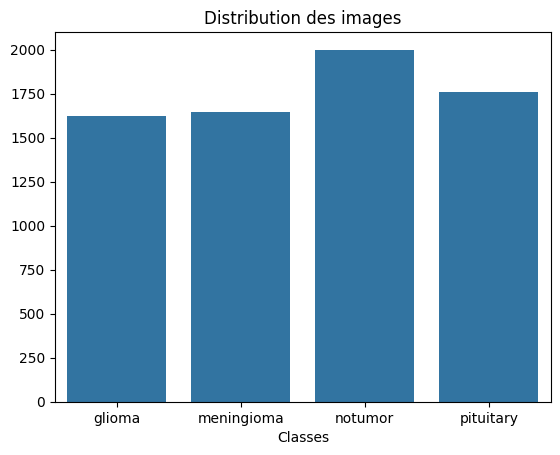

In [5]:
def afficher_distribution_classes(labels):
    classes, counts = np.unique(labels, return_counts=True)
    plt.figure()
    sns.barplot(x=classes, y=counts)
    plt.title('Distribution des images')
    plt.xlabel('Classes')
    plt.show()

afficher_distribution_classes(y)

#### Appliquer Label Encoging 

In [6]:
def applay_encoding(list):
    encoder = LabelEncoder()
    return encoder.fit_transform(list), encoder

y_encoder, label_encoder = applay_encoding(y)

num_classes = len(np.unique(y_encoder))

print(num_classes)

4


#### Split data

In [7]:
# Split test and train
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y_encoder, 
    test_size=0.3,
    stratify=y_encoder,
    random_state=RANDOM_KEY
)

# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,
    stratify=y_temp,
    random_state=RANDOM_KEY
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 3932
Validation : 984
Test : 2107


#### Appliquer One-Hot Encoding

In [8]:
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)

#### TensorFlow Dataset

In [9]:
# Create dataset avec params
def create_dataset(x_data, y_data, normalize_collback, is_use_shuffle = False, is_use_augmentation = False):
    dataset = (
        tf.data.Dataset
            .from_tensor_slices((x_data, y_data))
            .map(
                lambda image_path, label: load_image(image_path, label, normalize_collback),
                num_parallel_calls=AUTOTUNE
            )
    )

    # Shuffle les donnes
    if is_use_shuffle:
        dataset.shuffle(
            buffer_size=len(x_data), # pour utiliser tout les donnes dans mélange
            seed=RANDOM_KEY # Randomize logic
        )

    # Appliquer data augmentation s'est difiner
    if is_use_augmentation:
        data_augmentation = Sequential([
            layers.RandomRotation(0.03),
            layers.RandomZoom(0.1),
            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05
            )
        ]) 

        dataset.map(
            lambda image, label: (data_augmentation(image), label),
            num_parallel_calls=AUTOTUNE
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE) # Pour preparer les batch en paralille


# Load image and resize and normalize
def load_image(filename, label, normalize_collback):
    # load image
    raw = tf.io.read_file(filename)

    # converter image à matric de tensors avec 3 channels
    image = tf.image.decode_image(raw, channels=3)
    image.set_shape([None, None, 3]) # Déclarer le size image pour éviter error
    
    # Resize
    image = tf.image.resize(image, [SIZE_IMAGE, SIZE_IMAGE])

    # Normalization pour Base model
    image  = normalize_collback(image)
    return image, label

#### Visualiser les courbes d'apprentissage

In [10]:
def afficher_courbes_apprentissage(trensfoer_history, fine_tuning_history):
    # Accuracy
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    # Trensfoer Learning
    plt.plot(trensfoer_history["accuracy"], label="TL - Train")
    plt.plot(trensfoer_history["val_accuracy"], label="TL - Validation")

    # Fine-Tuning
    plt.plot(fine_tuning_history["accuracy"], label="FT - Train")
    plt.plot(fine_tuning_history["val_accuracy"], label="FT - Validation")

    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    # Trensfoer Learning
    plt.plot(trensfoer_history["loss"], label="TL - Train")
    plt.plot(trensfoer_history["val_loss"], label="TL - Validation")

    # Fine-Tuning
    plt.plot(fine_tuning_history["loss"], label="FT - Train")
    plt.plot(fine_tuning_history["val_loss"], label="FT - Validation")

    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [15]:
def build_transfer_model(base_model, normalize_collback, x_train, y_train, x_val, y_val, x_test,y_test):
    # ========== Dataset ==========
    # Trian
    train_ds = create_dataset(x_train, y_train, normalize_collback= normalize_collback, is_use_shuffle=True, is_use_augmentation=True)

    # Validation 
    val_ds = create_dataset(x_val, y_val, normalize_collback)

    # Test
    test_ds = create_dataset(x_test, y_test, normalize_collback)

    # charger base model pour trefer learning
    base = base_model(
        weights='imagenet', # loader les weights of train imagenet
        include_top=False, # remove classes of predicts base
        input_shape=(SIZE_IMAGE, SIZE_IMAGE, 3) # Size of input
    )

    base.trainable = False # franze all parametres of base model to not chnager on training

    # Dosser de model
    model_path = f'models/{base.__class__.__name__}'
    Path(model_path).mkdir(parents=True, exist_ok=True)

    # callbacks
    callbacks = [
        # Suvgarder le baset model pendant le training
        ModelCheckpoint(
            filepath=f"{model_path}/best_model.keras", # path de bast model
            monitor="val_loss", # monitore de comparisent
            save_best_only=True, # Sauvgarder le baset model sulment
            mode="min", # Suavgarder le model de min monitor
            verbose=1 # afficher sur terminal
        ),
        # Sauvgarder le étap de train si ariter pour pas perdet le étap de training
        BackupAndRestore(
            backup_dir=f"{model_path}/training_backup" # dosser de sauvgarder
        ),
        # Limiter le surapprentissage
        EarlyStopping(
            monitor="val_loss", # monitore de comparisent
            patience=5, # nomber des epochs sans augmentation de monitor
            restore_best_weights=True, # returner baset weights
            mode="min", # minimuent monitor
            verbose=1
        )
    ]

    # Model Archetecteur
    model = Sequential([
        base, # base model
        GlobalAveragePooling2D(), # minimizer les Featurs Map à vectore 

        # hiden layer
        Dense(128, activation="relu"),
        Dropout(0.3),

        # Output layer
        Dense(4, activation="softmax")
    ])

    model.summary()

    # =============== Transfer learning ===============
    # Config 
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Optimizer avec learninig rate
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train
    start_time = time.time()

    trensfoer_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks
    )

    train_time = time.time() - start_time
    print(f"Temps d'entraînement en Trensfor learning : {train_time / 60:.2f} minute")

    # =============== Fine Tuning ===============
    # Active with parametres Trainable
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False # Frazer tout les layers de 0 jusqua dérnier 30 layers

    # Reconfig model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), # Optimizer avec learninig rate tres petit
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train
    start_time = time.time()

    fine_tuning_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks  
    )

    train_time = time.time() - start_time
    print(f"Temps d'entraînement en Fine tuning : {train_time / 60:.2f} minute")

    # Visualiser les courbes d'apprentissage
    afficher_courbes_apprentissage(trensfoer_history.history, fine_tuning_history.history)

    # Évaluer le modèle avec test dataset
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
    print(f"Test Loss : {test_loss:.4f}")
    print(f"Test Accuracy : {test_accuracy:.4f}")

    # Préduction
    y_pred_probs = model.predict(test_ds) # Probabiliter sur les 4 classes
    # print(y_pred_probs[0])
    y_pred = np.argmax(y_pred_probs, axis=1) # index de max proba sur les column 

    # Évaluer les prédictions avec la Confusion Matrix
    classes = label_encoder.classes_

    cm = confusion_matrix(
        np.argmax(y_test, axis=1), # convert One hot encoding à label encoded
        y_pred,
        labels=np.arange(len(classes))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(cmap="Blues", xticks_rotation=45)
    plt.title("Matrice de confusion")
    plt.tight_layout()
    plt.show()

#### MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

...

87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.6906 - loss: 0.7921

2026-10-22 20:32:42.458370: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 20:32:42.595298: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 20:32:42.732827: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 815ms/step - accuracy: 0.6917 - loss: 0.7894

2026-10-22 20:33:13.148687: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 20:33:13.286860: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.32344, saving model to models/Functional/best_model.keras

Epoch 1: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.7856 - loss: 0.5556 - val_accuracy: 0.8780 - val_loss: 0.3234
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8797 - loss: 0.3312
Epoch 2: val_loss improved from 0.32344 to 0.27300, saving model to models/Functional/best_model.keras

Epoch 2: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.8835 - loss: 0.3127 - val_accuracy: 0.8974 - val_loss: 0.2730
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9169 - loss: 0.2385
Epoch 3: val_loss improved from 0.27300 to 0.25860, saving model to models/Functional/best_model.keras

Epoch 3: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.9128 - loss: 0.2392 - val_a

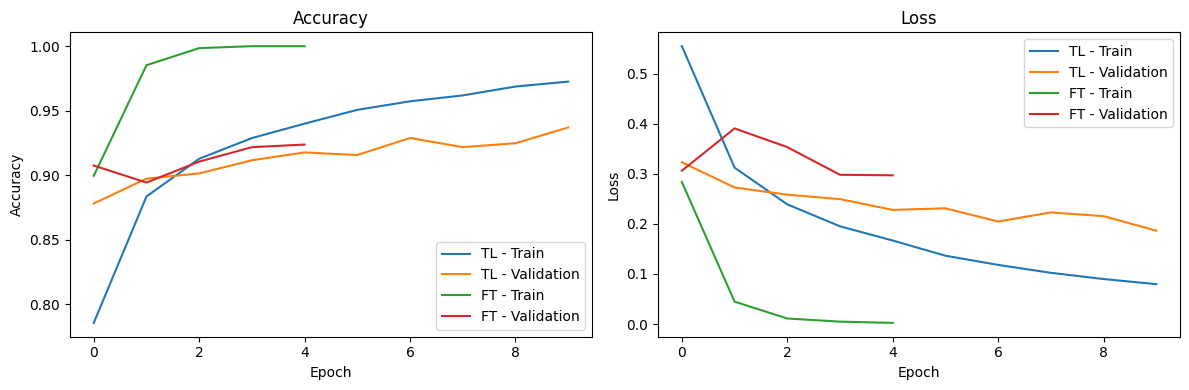

46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 703ms/step - accuracy: 0.8950 - loss: 0.2972

2026-10-22 20:35:52.478020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 20:35:52.614212: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 20:35:52.750698: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


47/47 ━━━━━━━━━━━━━━━━━━━━ 45s 964ms/step - accuracy: 0.9070 - loss: 0.2638
Test Loss : 0.2638
Test Accuracy : 0.9070
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step


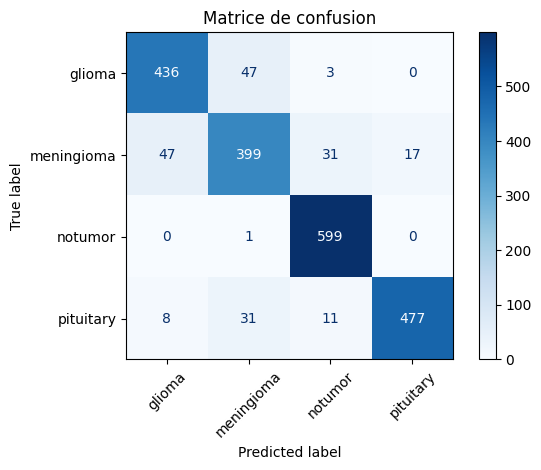

In [16]:
build_transfer_model(
    base_model=MobileNetV2,
    normalize_collback=preprocess_input,
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test
)